In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os


from tensorflow.keras.applications import MobileNetV2

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)


print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
dataset_path = "../dataset/level1_dataset"

In [4]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

train_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    validation_split=0.2,

    rotation_range=20,

    width_shift_range=0.15,

    height_shift_range=0.15,

    zoom_range=0.2,

    horizontal_flip=True,

    brightness_range=[0.8,1.2]

)


test_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    validation_split=0.2

)

In [18]:
IMG_SIZE = (224,224)

BATCH_SIZE = 32


train_data = train_datagen.flow_from_directory(

    dataset_path,

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    subset="training"

)


val_data = test_datagen.flow_from_directory(

    dataset_path,

    target_size=(224,224),

    batch_size=32,

    class_mode="categorical",

    subset="validation",

    shuffle=False
)

Found 2282 images belonging to 4 classes.
Found 569 images belonging to 4 classes.


In [6]:
class_names = list(
    train_data.class_indices.keys()
)


print(class_names)

print(
    "Number of classes:",
    len(class_names)
)

['Hazardous', 'Non-Recyclable', 'Organic', 'Recyclable']
Number of classes: 4


In [7]:
base_model = MobileNetV2(

    weights="imagenet",

    include_top=False,

    input_shape=(224,224,3)

)


base_model.trainable = False


print("MobileNetV2 loaded")

MobileNetV2 loaded


In [8]:
main_model = Sequential([

    base_model,


    GlobalAveragePooling2D(),


    Dense(
        128,
        activation="relu"
    ),


    Dropout(0.5),


    Dense(
        4,
        activation="softmax"
    )

])


main_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
main_model.compile(

    optimizer=Adam(
        learning_rate=0.0001
    ),

    loss="categorical_crossentropy",

    metrics=[
        "accuracy"
    ]

)

In [10]:
early_stop = EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True

)


checkpoint = ModelCheckpoint(

    "../models/main_category_model.keras",

    monitor="val_accuracy",

    save_best_only=True,

    mode="max"

)

In [11]:
history = main_model.fit(

    train_data,

    validation_data=val_data,

    epochs=20,

    callbacks=[
        early_stop,
        checkpoint
    ]

)

Epoch 1/20
10/72 ━━━━━━━━━━━━━━━━━━━━ 1:01 989ms/step - accuracy: 0.2969 - loss: 1.7824

C:\Disk D\Year 2 Semester 1\Year2Semester1\Year2Semester1\IT2011 AI & ML\AI ML Project\Waste-Classification-AI\venv\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


52/72 ━━━━━━━━━━━━━━━━━━━━ 18s 949ms/step - accuracy: 0.3374 - loss: 1.5698

C:\Disk D\Year 2 Semester 1\Year2Semester1\Year2Semester1\IT2011 AI & ML\AI ML Project\Waste-Classification-AI\venv\Lib\site-packages\PIL\TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


72/72 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.3576 - loss: 1.5058 - val_accuracy: 0.4938 - val_loss: 1.1859
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.4720 - loss: 1.1849 - val_accuracy: 0.5835 - val_loss: 1.0544
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.5754 - loss: 1.0740 - val_accuracy: 0.6204 - val_loss: 0.9788
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.6069 - loss: 0.9909 - val_accuracy: 0.6467 - val_loss: 0.9191
Epoch 5/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.6306 - loss: 0.9236 - val_accuracy: 0.6555 - val_loss: 0.8872
Epoch 6/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.6521 - loss: 0.8917 - val_accuracy: 0.6608 - val_loss: 0.8612
Epoch 7/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.6757 - loss: 0.8407 - val_accuracy: 0.6819 - val_loss: 0.8317
Epoch 8/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.6727 - loss: 0.8164 - val_accuracy: 0.6661 - val_loss: 0.8233
Ep

In [12]:
from tensorflow.keras.models import load_model

main_model = load_model(
    "../models/main_category_model.keras"
)

print("Model loaded")

Model loaded


In [13]:
base_model = main_model.layers[0]

base_model.trainable = True


for layer in base_model.layers[:-50]:
    layer.trainable = False


print("Fine tuning enabled")

Fine tuning enabled


In [14]:
from tensorflow.keras.optimizers import Adam


main_model.compile(

    optimizer=Adam(
        learning_rate=0.00001
    ),

    loss="categorical_crossentropy",

    metrics=["accuracy"]

)

In [15]:
fine_history = main_model.fit(

    train_data,

    validation_data=val_data,

    epochs=10,

    callbacks=[
        checkpoint,
        early_stop
    ]

)

Epoch 1/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 102s 1s/step - accuracy: 0.6595 - loss: 0.8649 - val_accuracy: 0.7047 - val_loss: 0.7466
Epoch 2/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - accuracy: 0.6862 - loss: 0.8026 - val_accuracy: 0.7135 - val_loss: 0.7351
Epoch 3/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 89s 1s/step - accuracy: 0.7165 - loss: 0.7422 - val_accuracy: 0.7153 - val_loss: 0.7286
Epoch 4/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 96s 1s/step - accuracy: 0.7274 - loss: 0.7112 - val_accuracy: 0.7153 - val_loss: 0.7259
Epoch 5/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.7305 - loss: 0.7038 - val_accuracy: 0.7083 - val_loss: 0.7263
Epoch 6/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 96s 1s/step - accuracy: 0.7384 - loss: 0.6845 - val_accuracy: 0.7065 - val_loss: 0.7211
Epoch 7/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 94s 1s/step - accuracy: 0.7542 - loss: 0.6515 - val_accuracy: 0.7100 - val_loss: 0.7191
Epoch 8/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.7612 - loss: 0.6408 - val_accuracy: 0.7188 - val_loss

 4/18 ━━━━━━━━━━━━━━━━━━━━ 7s 541ms/step

C:\Disk D\Year 2 Semester 1\Year2Semester1\Year2Semester1\IT2011 AI & ML\AI ML Project\Waste-Classification-AI\venv\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


18/18 ━━━━━━━━━━━━━━━━━━━━ 11s 580ms/step


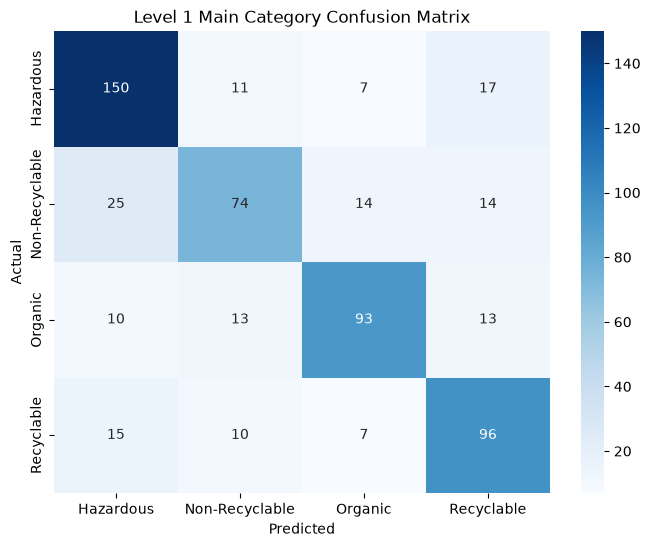

In [19]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


predictions = main_model.predict(val_data)

y_pred = np.argmax(predictions, axis=1)

y_true = val_data.classes


cm = confusion_matrix(
    y_true,
    y_pred
)


plt.figure(figsize=(8,6))


sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)


plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Level 1 Main Category Confusion Matrix")

plt.show()

In [17]:
main_model.save(
    "../models/final_main_category_model.keras"
)

print("Saved")

Saved
